# Finding the right passage: semantic retrieval for documentation

**Author**: albertpinto · UCB MLAI capstone · [Repository](https://github.com/albertpinto/MLAI-UCB-Capstone)

This notebook analyses how well different search methods find the passage that answers a question, on the Constitution of India (402 pages).
The application itself (ingestion, search, answers, the web app) is described in the [README](../README.md); this notebook holds the data analysis.

**Contents**
1. Business understanding
2. Data and cleaning
3. Descriptive statistics
4. How success is measured
5. Comparing the search methods
6. Are the differences real? (inference)
7. Modeling: grid search and cross-validation
8. Findings and recommendations

## 1. Business understanding

**The problem.** People ask for help in everyday words ("Can the government take away my life or personal freedom?"), while documents use formal terms
("No person shall be deprived of his life or personal liberty except according to procedure established by law"). A keyword search misses
such matches, so people give up or get a wrong answer.

**Who cares.** Anyone who answers questions from a large body of documents: support teams, policy and legal staff, and the people who ask them.
A search that puts the right passage first saves time, and an answer that is *grounded* in the documents (with a citation, or an honest
"not found") is more trustworthy than one a language model invents.

**What success looks like (in plain words).**
- For most questions, the right section appears among the first few results ("Recall at 5").
- When it does, it appears near the top ("Mean reciprocal rank").
- The method has to beat plain keyword search by a clear margin, or it is not worth the extra cost.

**The data we can use.** 62 questions, each labelled with the sentence that answers it, divided into *train* and *test* by Part of the Constitution,
so that nothing the system was tuned on is also used to judge it.

## 2. Data and cleaning

In [1]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pypdf import PdfReader
from scipy import stats
from sklearn.model_selection import GroupKFold

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
rng = np.random.default_rng(0)          # one seed, so every resample and chart is repeatable

K = 5                                   # "the first K results": a person reads a handful, not a hundred
DATA = Path("data")                     # written by eval/grid_search.py
QUESTIONS = Path("../eval/questions.json")

Three files feed this notebook. `eval/questions.json` holds the labelled questions. `data/eval_results.json` holds, for every question, the rank at which
each search method first shows a correct section. `data/grid_results.csv` holds the same for many settings of each method.
Both are written by `eval/grid_search.py` from the live index, so this notebook runs without the app or any model.

In [2]:
questions = pd.DataFrame(json.loads(QUESTIONS.read_text()))
results = json.loads((DATA / "eval_results.json").read_text())
grid = pd.read_csv(DATA / "grid_results.csv")

print(f"Searched document: {results['document']}  ({results['chunks']:,} chunks in {results['sections']} sections)")
questions.head(3)

Searched document: Constitution of India (2024).pdf  (2,358 chunks in 524 sections)


,id,question,evidence,split,note
0,q01,Can the government take away my life or person...,[except according to procedure established by ...,train,"Part III; drafted from the text, not independent"
1,q02,Does the law treat everyone equally?,[equality before the law or the equal protecti...,train,"Part III; drafted from the text, not independent"
2,q03,Can I be treated differently because of my rel...,[shall not discriminate against any citizen on...,train,"Part III; drafted from the text, not independent"


**Cleaning the question table.** Trim stray whitespace, derive simple features (length of each question and of its evidence phrase) and check for problems:
empty text, questions without evidence, duplicates, and evidence that cannot be found in the indexed text (such a question cannot be scored).

In [3]:
questions["question"] = questions["question"].str.strip().str.replace(r"\s+", " ", regex=True)
questions["words"] = questions["question"].str.split().str.len()
questions["n_evidence"] = questions["evidence"].str.len()
questions["evidence_words"] = questions["evidence"].apply(lambda e: np.mean([len(x.split()) for x in e]) if e else 0)

checks = pd.Series({
    "questions": len(questions),
    "empty question text": int(questions["question"].eq("").sum()),
    "questions without evidence": int(questions["n_evidence"].eq(0).sum()),
    "duplicate questions": int(questions["question"].str.lower().duplicated().sum()),
    "evidence not found in the index": len(questions) - results["questions"],
    "train questions": int(questions["split"].eq("train").sum()),
    "test questions": int(questions["split"].eq("test").sum()),
}, name="count")
checks.to_frame()

,count
questions,62
empty question text,0
questions without evidence,0
duplicate questions,0
evidence not found in the index,0
train questions,34
test questions,28


Every question is usable (nothing is empty, duplicated or unresolved), so no question had to be dropped.

**Cleaning the source text.** The text of the Constitution does not come out of the PDF cleanly: every page carries amendment footnotes
("Ins. by the Constitution (Forty-second Amendment) Act, 1976, s. 2 ...") that would otherwise be searched as if they were law. The project removes them while it parses the PDF.
Here is that step on one real page, using the same functions the application uses.

In [4]:
from capstone.chunking import clean_text
from capstone.parsing import strip_footnotes

pdf = next(Path("../data/docs").glob("Constitution*.pdf"))
pages = PdfReader(pdf).pages

# The first page (after the preamble) that has footnote lines to remove.
for number in range(25, 120):
    raw = pages[number].extract_text()
    cleaned = clean_text(strip_footnotes(raw))
    if len(cleaned) < len(raw) * 0.97:
        break

removed = [line for line in raw.split("\n") if line not in cleaned.split("\n")]
print(f"PDF page {number + 1}: {len(raw.split(chr(10)))} lines extracted, {len(cleaned.split(chr(10)))} kept, {len(raw) - len(cleaned)} characters removed.\n")
print("Examples of what was removed:")
for line in removed[:4]:
    print("  -", line[:110])

PDF page 32: 19 lines extracted, 17 kept, 114 characters removed.

Examples of what was removed:
  - THE  CONSTITUTION OF INDIA 
  -  
  - 1. Subs. by the Constitution (Forty-second Amendment) Act, 1976, s.2, for "SOVEREIGN 
  - DEMOCRATIC REPUBLIC" (w.e.f. 3-1-1977).


## 3. Descriptive statistics

How are the questions spread over the document, and how long are they? The *Part* matters because the train/test split is made by Part: a Part that holds a test question is never used
for training, so tuning cannot see the answers.

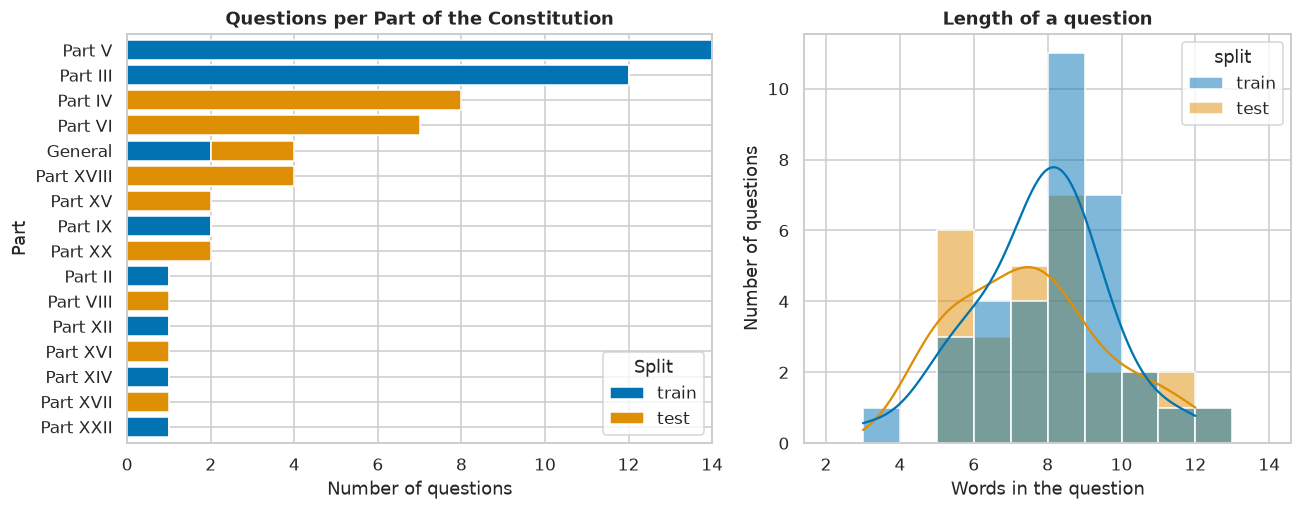

split                 test  train
words          count  28.0   34.0
               mean    7.5    7.8
               std     2.0    1.8
               min     5.0    3.0
               25%     6.0    7.0
               50%     7.5    8.0
               75%     8.2    9.0
               max    12.0   12.0
n_evidence     count  28.0   34.0
               mean    1.0    1.0
               std     0.0    0.0
               min     1.0    1.0
               25%     1.0    1.0
               50%     1.0    1.0
               75%     1.0    1.0
               max     1.0    1.0
evidence_words count  28.0   34.0
               mean   11.3   12.0
               std     4.2    4.2
               min     3.0    7.0
               25%     8.0    8.0
               50%    11.0   12.5
               75%    15.2   15.0
               max    18.0   24.0

In [5]:
base = grid[grid["family"] == "base"][["id", "part", "split"]]
per_question = questions.merge(base, on=["id", "split"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
counts = pd.crosstab(per_question["part"], per_question["split"])[["train", "test"]]
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
counts.plot.barh(stacked=True, ax=axes[0], color=sns.color_palette("colorblind")[:2], width=0.8)
axes[0].invert_yaxis()
axes[0].set(title="Questions per Part of the Constitution", xlabel="Number of questions", ylabel="Part")
axes[0].legend(title="Split")

sns.histplot(data=per_question, x="words", hue="split", bins=range(2, 15), kde=True, ax=axes[1])
axes[1].set(title="Length of a question", xlabel="Words in the question", ylabel="Number of questions")
plt.tight_layout()
plt.show()

per_question.groupby("split")[["words", "n_evidence", "evidence_words"]].describe().T.round(1)

**What the data looks like.**
- There are **62 questions** over **16 Parts** of the Constitution: 34 for training and tuning, 28 for testing. Whole Parts are assigned to one side. The one exception is "General", a catch-all label for sections with no Part, which has questions on both sides; it is treated like a test Part, so none of its text is used for training.
- Questions are **short, about 8 words**, much like what a person types, and each has exactly one evidence sentence (11 to 12 words long). They were written by reading the text, so they are not an independent sample of real user questions.
- The split is **uneven**: Parts V and III hold 26 of the 62 questions and are all on the training side, while the test set leans on Parts IV and VI (15 of its 28 questions). Test results may therefore say more about those Parts than about the whole document, one reason to be careful with small differences below.

## 4. How success is measured

Each search method returns a ranked list of *sections*. A section is **correct** if it contains the labelled evidence sentence. Three measures describe the list:

| Measure | In plain words | Why it fits this problem |
|---|---|---|
| **Recall@5** | Of the correct sections, the share that appear in the first 5 results. | A person reads the first few results. It is the most direct answer to "did the search find it?". |
| **MRR** (mean reciprocal rank) | Average of 1 / (position of the first correct section). 1.0 means always first, 0.5 second, 0.1 tenth. | It rewards putting the right section *first*, so it separates two methods that both "find it somewhere in the top 5". |
| **nDCG@5** | Credit for each correct section in the top 5, discounted the lower it sits. | The same idea as Recall, but a correct result at position 1 counts more than at position 5. |

We do not use accuracy or F1: there is no yes/no prediction here, only a ranking, and almost every section is "not correct". When a question has one correct section, Recall@5 equals the
share of questions answered in the top 5, which we call **Hit@5** below; it lets us put error bars on the results.
We use **MRR to choose settings** (section 7) because it changes smoothly when a result moves up or down, while Hit@5 only changes when a result crosses position 5.

## 5. Comparing the search methods

Eight methods, all searching the same chunks: **BM25** (keyword matching), the **base** embedding model (MiniLM, as downloaded), the same model **fine-tuned** on the corpus,
a **hybrid** of BM25 and the base model, a cross-encoder **rerank** on top of the hybrid or of the base model, and the same with a **knowledge graph** adding candidates.
Results below are on the **test questions only**: the questions of Parts the fine-tuned model never saw.

In [6]:
SHORT = {"bm25": "BM25", "base": "Base MiniLM", "tuned": "Fine-tuned MiniLM", "hybrid": "Hybrid (BM25 + base)", "rerank": "Hybrid + rerank",
         "base_rerank": "Base + rerank", "base_graph": "Base + graph", "base_rerank_graph": "Base + graph + rerank"}

# One row per question and method: the rank of the first correct section, then Hit@5 and reciprocal rank.
per_q = pd.DataFrame(results["per_question"])
ranks = pd.DataFrame(per_q["ranks"].tolist(), index=per_q["id"])
long = (ranks.join(per_q.set_index("id")[["split", "question"]]).reset_index()
        .melt(id_vars=["id", "split", "question"], var_name="retriever", value_name="rank"))
long["hit5"] = (long["rank"] <= K).astype(float)
long["rr"] = (1 / long["rank"]).fillna(0)
test = long[long["split"] == "test"]

# The headline table: the application's own metrics on the test split.
summary = pd.DataFrame(results["test_summary"]).T[["recall", "mrr", "ndcg"]].astype(float)
summary.index = summary.index.map(SHORT)
summary.columns = ["Recall@5", "MRR", "nDCG@5"]
summary.sort_values("MRR", ascending=False).round(3)

,Recall@5,MRR,nDCG@5
Base + rerank,0.911,0.780,0.795
Base + graph + rerank,0.911,0.777,0.792
Hybrid + rerank,0.964,0.771,0.815
Base MiniLM,0.875,0.696,0.720
Base + graph,0.875,0.681,0.711
Fine-tuned MiniLM,0.911,0.644,0.696
Hybrid (BM25 + base),0.786,0.562,0.592
BM25,0.518,0.359,0.379


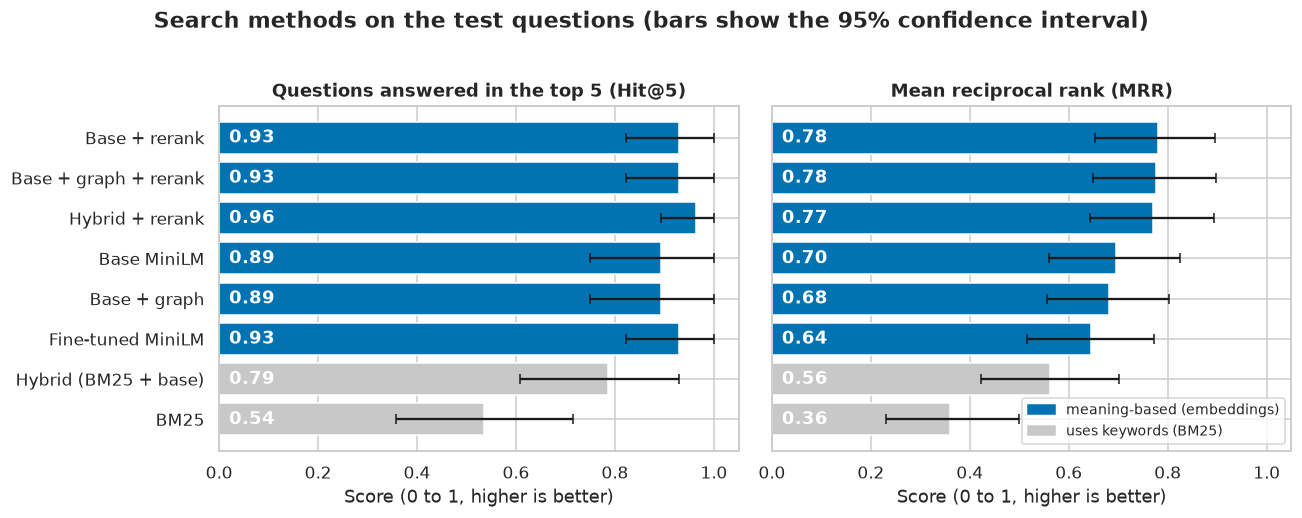

In [7]:
def bootstrap_ci(values, n=10_000):
    """95% confidence interval of the mean, by resampling the questions with replacement."""
    values = np.asarray(values, dtype=float)
    means = rng.choice(values, size=(n, len(values))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

stats_table = test.groupby("retriever").agg(hit5=("hit5", "mean"), mrr=("rr", "mean"))
for column, source in (("hit5", "hit5"), ("mrr", "rr")):
    ci = test.groupby("retriever")[source].apply(bootstrap_ci)
    stats_table[f"{column}_lo"], stats_table[f"{column}_hi"] = ci.map(lambda c: c[0]), ci.map(lambda c: c[1])
stats_table = stats_table.sort_values("mrr")
names = stats_table.index.map(SHORT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, column, title in ((axes[0], "hit5", "Questions answered in the top 5 (Hit@5)"), (axes[1], "mrr", "Mean reciprocal rank (MRR)")):
    error = [stats_table[column] - stats_table[f"{column}_lo"], stats_table[f"{column}_hi"] - stats_table[column]]
    colours = ["#c8c8c8" if n in ("BM25", "Hybrid (BM25 + base)") else sns.color_palette("colorblind")[0] for n in names]   # grey: methods that rely on keywords
    ax.barh(names, stats_table[column], xerr=error, color=colours, capsize=3, edgecolor="white")
    ax.set(title=title, xlim=(0, 1.05), xlabel="Score (0 to 1, higher is better)")
    for y, value in enumerate(stats_table[column]):
        ax.text(0.02, y, f"{value:.2f}", va="center", color="white", fontweight="bold")
axes[0].set_ylabel("")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=sns.color_palette("colorblind")[0], label="meaning-based (embeddings)"), Patch(color="#c8c8c8", label="uses keywords (BM25)")], loc="lower right", fontsize=9)
fig.suptitle("Search methods on the test questions (bars show the 95% confidence interval)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**What the charts show (test questions).**
- **Meaning-based search beats keyword search by a wide margin.** BM25 puts a correct section in the top 5 for 54% of questions (15 of 28; Recall@5 0.52). The base model does so for 89%, and with the cross-encoder rerank 93% to 96%.
- **Reranking helps at the top of the list.** The share of questions where the correct section is the very first result is 21% for BM25, 57% for the base model and **68%** for both rerank pipelines.
- **The three "extras" did not beat the simple base model.** The hybrid is worse than the base model alone (MRR 0.56 against 0.70): BM25's weak ranking dilutes the good one. The knowledge graph changes nothing (0.68 against 0.70). The fine-tuned model finds the answer about as often (Hit@5 0.93; Recall@5 0.91 against 0.88 for the base model, one more question) but ranks it lower (MRR 0.64 against 0.70).
- The two tables differ slightly in definition: the application's **Recall@5** counts the share of correct sections found, so a question with two correct sections can count as half; **Hit@5** counts a question as answered if any correct section is in the top 5, which is what lets us draw the error bars.
- The error bars are wide (28 questions). Bars that overlap, such as the three rerank pipelines, cannot be told apart.

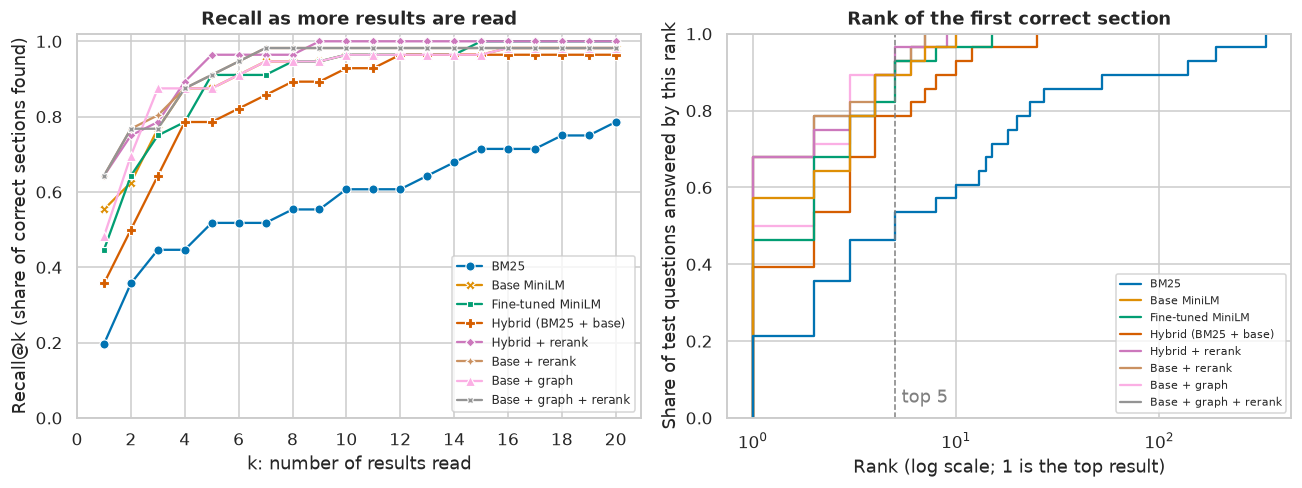

In [8]:
# How far down the list is the right section? Share of questions answered within each rank (log scale: the tail is long).
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

curves = pd.DataFrame({SHORT[n]: v["curve"] for n, v in results["test_summary"].items()}, index=range(1, 21)).rename_axis("k")
curve_long = curves.reset_index().melt(id_vars="k", var_name="Method", value_name="Recall")
sns.lineplot(data=curve_long, x="k", y="Recall", hue="Method", style="Method", markers=True, dashes=False, ax=axes[0])
axes[0].set(title="Recall as more results are read", xlabel="k: number of results read", ylabel="Recall@k (share of correct sections found)", ylim=(0, 1.02))
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_xticks(range(0, 21, 2))

sns.ecdfplot(data=test.assign(Method=test["retriever"].map(SHORT)), x="rank", hue="Method", log_scale=True, ax=axes[1])
sns.move_legend(axes[1], "lower right", fontsize=7, title=None)
axes[1].axvline(K, color="grey", ls="--", lw=1)
axes[1].text(K * 1.08, 0.04, "top 5", color="grey")
axes[1].set(title="Rank of the first correct section", xlabel="Rank (log scale; 1 is the top result)", ylabel="Share of test questions answered by this rank")
plt.tight_layout()
plt.show()

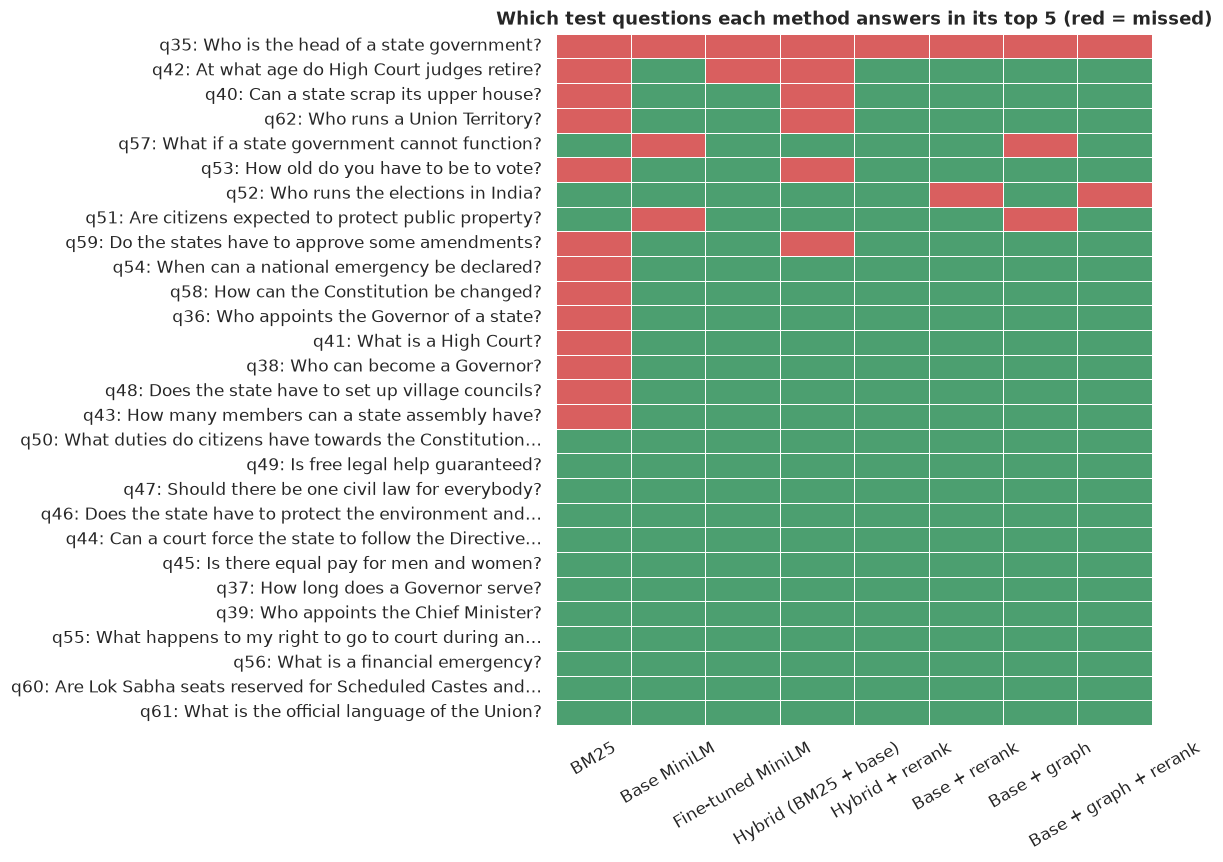

In [9]:
# Which questions does each method miss? One row per test question; green = a correct section is in the top 5.
hits = test.pivot(index="id", columns="retriever", values="hit5")[list(SHORT)].rename(columns=SHORT)
hits = hits.loc[hits.sum(axis=1).sort_values().index]
labels = {row.id: f"{row.id}: {textwrap.shorten(row.question, 56, placeholder='…')}" for row in test.drop_duplicates("id").itertuples()}
hits.index = hits.index.map(labels)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hits, cmap=["#d95f5f", "#4c9f70"], cbar=False, linewidths=0.6, linecolor="white", ax=ax)
ax.set(title="Which test questions each method answers in its top 5 (red = missed)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Where the methods fail.**
- BM25 misses **13 of 28** questions. 12 of those are answered by the base model, which is the gap a meaning-based search is meant to close: short everyday questions ("Who runs a Union Territory?", "How old do you have to be to vote?") whose words appear in many sections of the document, so keyword matching cannot tell which section is about it.
- **q35 "Who is the head of a state government?" is missed by all eight methods.** The base model puts the right section 6th (just outside the top 5), the reranker leaves it at 6th, and BM25 puts it 334th. A likely reason is that the text speaks of the *Governor* and the executive power of the State, not of a "head of government". It is a good example of a question that needs the system to bridge everyday words to formal ones.
- The reranker fixes some questions and breaks others (q52 "Who runs the elections in India?" is answered by the base model but not by the pipelines that rerank it), which is why its benefit is small and uncertain.

## 6. Are the differences real? (inference)

With 28 test questions, a gap of one or two questions is easily luck. Two checks, both **paired** (each method is compared with another on the *same* questions):

- a **bootstrap confidence interval** for the difference in reciprocal rank: resample the questions 10,000 times; if the interval excludes 0, the gap is unlikely to be luck;
- a **Wilcoxon signed-rank test**, which asks the same question without assuming a bell-shaped distribution. Because we make several comparisons, the p-value is multiplied by the number of comparisons (Bonferroni), which makes it harder to call a gap real.

In [10]:
def paired(a, b, data):
    """Method a minus method b, on the questions in `data`, by reciprocal rank."""
    wide = data.pivot(index="id", columns="retriever", values="rr")
    diff = (wide[a] - wide[b]).to_numpy()
    boots = rng.choice(diff, size=(10_000, len(diff))).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    p = stats.wilcoxon(diff).pvalue if np.any(diff != 0) else 1.0
    return {"comparison": f"{SHORT[a]}  vs  {SHORT[b]}", "questions": len(diff), "mean difference": diff.mean(), "95% CI low": lo, "95% CI high": hi, "p-value": p}

pairs = [("base_rerank", "bm25"), ("base", "bm25"), ("base_rerank", "base"), ("tuned", "base"), ("base_graph", "base"), ("hybrid", "base")]
rows = pd.DataFrame([paired(a, b, test) for a, b in pairs])
rows["p (Bonferroni)"] = (rows["p-value"] * len(rows)).clip(upper=1)
rows["real gap?"] = np.where((rows["95% CI low"] > 0) | (rows["95% CI high"] < 0), "yes", "not shown")
rows.round(3).set_index("comparison")

,questions,mean difference,95% CI low,95% CI high,p-value,p (Bonferroni),real gap?
comparison,,,,,,,
Base + rerank vs BM25,28,0.421,0.272,0.570,0.000,0.001,yes
Base MiniLM vs BM25,28,0.337,0.150,0.520,0.003,0.017,yes
Base + rerank vs Base MiniLM,28,0.084,-0.073,0.249,0.255,1.000,not shown
Fine-tuned MiniLM vs Base MiniLM,28,-0.052,-0.208,0.102,0.521,1.000,not shown
Base + graph vs Base MiniLM,28,-0.015,-0.074,0.036,0.683,1.000,not shown
Hybrid (BM25 + base) vs Base MiniLM,28,-0.134,-0.304,0.040,0.170,1.000,not shown


In [11]:
# The methods that were not trained can also be compared on all 62 questions, which gives the tests more power.
untrained = long[long["retriever"].isin(["bm25", "base", "hybrid", "base_rerank", "base_graph"])]
pairs_all = [("base_rerank", "bm25"), ("base", "bm25"), ("base_rerank", "base"), ("base_graph", "base"), ("hybrid", "base")]
rows_all = pd.DataFrame([paired(a, b, untrained) for a, b in pairs_all])
rows_all["p (Bonferroni)"] = (rows_all["p-value"] * len(rows_all)).clip(upper=1)
rows_all["real gap?"] = np.where((rows_all["95% CI low"] > 0) | (rows_all["95% CI high"] < 0), "yes", "not shown")
rows_all.round(3).set_index("comparison")

,questions,mean difference,95% CI low,95% CI high,p-value,p (Bonferroni),real gap?
comparison,,,,,,,
Base + rerank vs BM25,62,0.386,0.287,0.488,0.000,0.000,yes
Base MiniLM vs BM25,62,0.339,0.232,0.446,0.000,0.000,yes
Base + rerank vs Base MiniLM,62,0.047,-0.054,0.146,0.374,1.000,not shown
Base + graph vs Base MiniLM,62,-0.007,-0.053,0.038,0.797,1.000,not shown
Hybrid (BM25 + base) vs Base MiniLM,62,-0.140,-0.235,-0.046,0.005,0.024,yes


**Reading the two tables.**
- **Real gaps** (the interval excludes 0): the base model beats BM25 by 0.34 reciprocal rank (95% CI 0.15 to 0.52 on the test questions; 0.23 to 0.45 on all 62), and base + rerank beats BM25 by 0.42 (0.27 to 0.57; 0.29 to 0.49 on 62). These survive the Bonferroni correction. Keyword search is clearly worse on this corpus.
- The **hybrid is worse than the base model alone**: not shown on the 28 test questions (-0.13, CI -0.30 to 0.04) but clear on all 62 (-0.14, CI -0.24 to -0.05; p = 0.024 after correction).
- **Not shown** (the interval includes 0): base + rerank against the base model (+0.08 on test, +0.05 on 62), the fine-tuned model against the base model (-0.05), and the graph against the base model (-0.015). The reranker may well help, but 28 or 62 questions cannot prove it. Questions differ a lot in how much the reranker changes them (the paired difference has a standard deviation of about 0.40), so a rough power estimate says about 200 independent questions would be needed to confirm a gap of 0.08 and about 500 for a gap of 0.05.
- The fine-tuned model is not compared on the 62 questions because it was trained on the train Parts.

## 7. Modeling: grid search and cross-validation

**What is being modeled.** The "models" are retrieval pipelines; their *hyperparameters* are settings nobody can know in advance:

| Pipeline | Settings searched |
|---|---|
| **BM25** (keywords) | `k1` (how quickly repeated words stop counting) × `b` (how much long chunks are penalised): 12 combinations |
| **Hybrid** (BM25 + base model) | the constant of the reciprocal-rank fusion `rrf_k`: 4 values |
| **Base + rerank** | how many top results the cross-encoder re-scores (`depth`): 5 values |
| **Base model** | none (it is used as downloaded) |

Every setting was scored on every one of the 62 questions (`eval/grid_search.py`). The fine-tuned model is **not** part of this section: it was trained on the train Parts, so scoring it
on those questions would be cheating.

**The metric for choosing is MRR** (section 4), reported next to Recall@5 and nDCG@5.

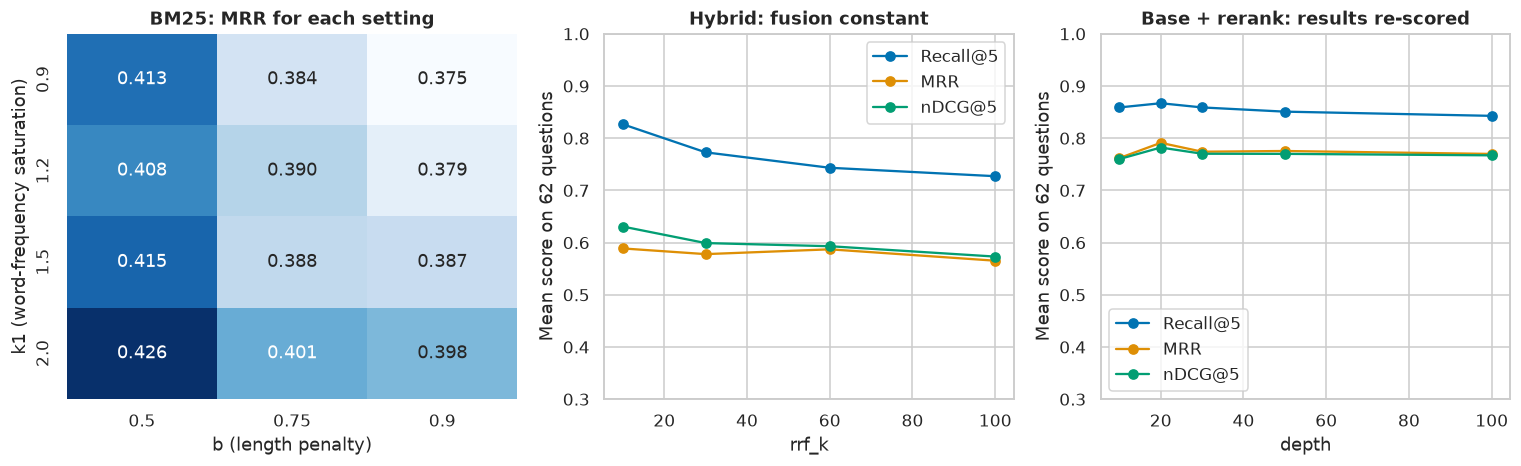

In [12]:
# A readable name for each setting, e.g. "k1=1.5, b=0.75".
grid["config"] = grid.apply(lambda r: ", ".join(f"{p}={r[p]:g}" for p in ("k1", "b", "rrf_k", "depth") if pd.notna(r[p])) or "as downloaded", axis=1)
all_questions = grid[grid["family"] == "base"][["id", "part"]].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})

bm25_mrr = grid[grid["family"] == "bm25"].groupby(["k1", "b"])["mrr"].mean().unstack()
sns.heatmap(bm25_mrr, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="BM25: MRR for each setting", xlabel="b (length penalty)", ylabel="k1 (word-frequency saturation)")

for ax, family, column, title, xlabel in ((axes[1], "hybrid", "rrf_k", "Hybrid: fusion constant", "rrf_k"), (axes[2], "base_rerank", "depth", "Base + rerank: results re-scored", "depth")):
    sub = grid[grid["family"] == family].groupby(column)[["recall", "mrr", "ndcg"]].mean().rename(columns={"recall": "Recall@5", "mrr": "MRR", "ndcg": "nDCG@5"})
    sub.plot(marker="o", ax=ax)
    ax.set(title=title, xlabel=xlabel, ylabel="Mean score on 62 questions", ylim=(0.3, 1))
plt.tight_layout()
plt.show()

**What the grid search shows (all 62 questions).**
- **BM25** is not rescued by tuning: the 12 settings span MRR 0.375 to 0.426 (best: `k1=2.0`, `b=0.5`, which counts repeated words more and penalises long chunks less). Even the best setting is far below the base model's 0.728.
- **Hybrid**: MRR is flat (0.57 to 0.59) for every fusion constant, and Recall@5 falls from 0.83 at `rrf_k=10` to 0.73 at 100. The best hybrid (Recall@5 0.83, MRR 0.59) only matches the base model's Recall@5 (0.83) and is clearly behind it on MRR (0.73).
- **Rerank depth** barely matters: re-scoring the top 20 gives MRR 0.791, the top 100 gives 0.770. Re-scoring more candidates gives the cross-encoder more chances to promote a wrong one, so a modest depth is enough. The differences are about 0.03.

**Cross-validation, grouped by Part.** Picking the best setting on all 62 questions and then reporting its score on the same questions is optimistic. So we cross-validate: split the questions into
5 folds so that **all questions of a Part stay in the same fold** (a method is never tuned on a Part and judged on it), choose the best setting on four folds, and score it on the fifth.
Every question is held out exactly once, so the pooled score is an honest estimate of how a tuned method performs on Parts it has not seen.

In [13]:
METRICS = ["recall", "mrr", "ndcg"]
DEFAULT = {"bm25": "k1=1.5, b=0.75", "hybrid": "rrf_k=60", "base_rerank": "depth=30", "base": "as downloaded"}   # the settings the application uses

held_out, chosen = [], []
folds = GroupKFold(n_splits=5).split(all_questions, groups=all_questions["part"])
for fold, (train_at, test_at) in enumerate(folds, start=1):
    train_ids, test_ids = set(all_questions.loc[train_at, "id"]), set(all_questions.loc[test_at, "id"])
    # Grid search on the training folds: the setting with the best mean MRR in each family.
    best = grid[grid["id"].isin(train_ids)].groupby(["family", "config"])["mrr"].mean().groupby(level="family").idxmax()
    for family, (_, config) in best.items():
        rows_ = grid[(grid["family"] == family) & (grid["config"] == config) & grid["id"].isin(test_ids)].assign(fold=fold, kind="tuned in the training folds")
        held_out.append(rows_)
        chosen.append({"fold": fold, "family": family, "chosen setting": config, "held-out parts": ", ".join(sorted(all_questions.loc[test_at, "part"].unique()))})
for family, config in DEFAULT.items():
    held_out.append(grid[(grid["family"] == family) & (grid["config"] == config)].assign(kind="default setting"))

cv = pd.concat(held_out)
cv_table = cv.groupby(["family", "kind"])[METRICS].mean().rename(columns={"recall": "Recall@5", "mrr": "MRR", "ndcg": "nDCG@5"})
cv_table.index = cv_table.index.set_levels(cv_table.index.levels[0].map({"bm25": "BM25", "base": "Base MiniLM", "hybrid": "Hybrid (BM25 + base)", "base_rerank": "Base + rerank"}), level=0)
cv_table.round(3)

Recall@5    MRR  nDCG@5
family               kind                                                
Base MiniLM          default setting                 0.827  0.728   0.717
                     tuned in the training folds     0.827  0.728   0.717
Base + rerank        default setting                 0.859  0.774   0.770
                     tuned in the training folds     0.867  0.791   0.782
BM25                 default setting                 0.480  0.388   0.381
                     tuned in the training folds     0.488  0.414   0.400
Hybrid (BM25 + base) default setting                 0.743  0.587   0.593
                     tuned in the training folds     0.778  0.581   0.603

In [14]:
# Is a tuned setting really better than the default, on questions it was not tuned on? Paired bootstrap per family.
gain = []
for family in ("bm25", "hybrid", "base_rerank"):
    tuned_rr = cv[(cv["family"] == family) & (cv["kind"] == "tuned in the training folds")].set_index("id")["mrr"]
    default_rr = cv[(cv["family"] == family) & (cv["kind"] == "default setting")].set_index("id")["mrr"]
    diff = (tuned_rr - default_rr.loc[tuned_rr.index]).to_numpy()
    boots = rng.choice(diff, size=(10_000, len(diff))).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    gain.append({"method": family, "MRR gain from tuning": diff.mean(), "95% CI low": lo, "95% CI high": hi, "real gain?": "yes" if lo > 0 else "not shown"})
pd.DataFrame(gain).set_index("method").round(3)

,MRR gain from tuning,95% CI low,95% CI high,real gain?
method,,,,
bm25,0.026,-0.001,0.060,not shown
hybrid,-0.007,-0.034,0.017,not shown
base_rerank,0.017,-0.001,0.042,not shown


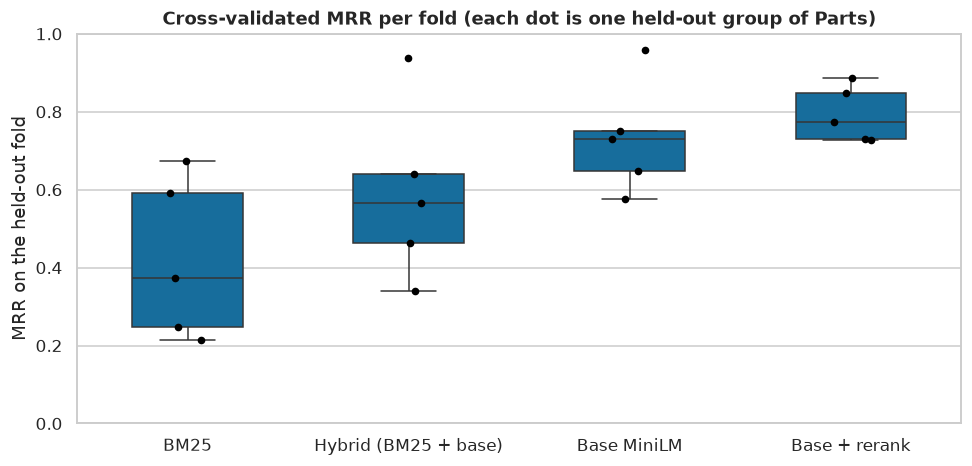

,base,base_rerank,bm25,hybrid,held-out parts
fold,,,,,
1,as downloaded,depth=20,"k1=2, b=0.5",rrf_k=10,Part V
2,as downloaded,depth=20,"k1=1.5, b=0.5",rrf_k=10,Part III
3,as downloaded,depth=20,"k1=2, b=0.5",rrf_k=60,"Part IV, Part XII, Part XV, Part XVII"
4,as downloaded,depth=20,"k1=2, b=0.5",rrf_k=10,"Part VI, Part VIII, Part XVI, Part XX, Part XXII"
5,as downloaded,depth=20,"k1=2, b=0.5",rrf_k=60,"General, Part II, Part IX, Part XIV, Part XVIII"


In [15]:
# The same result per fold, to see how much it depends on which Parts were held out.
per_fold = (cv[cv["kind"] == "tuned in the training folds"].groupby(["family", "fold"])["mrr"].mean().reset_index()
            .assign(Method=lambda d: d["family"].map({"bm25": "BM25", "base": "Base MiniLM", "hybrid": "Hybrid (BM25 + base)", "base_rerank": "Base + rerank"})))
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.boxplot(data=per_fold, x="Method", y="mrr", order=["BM25", "Hybrid (BM25 + base)", "Base MiniLM", "Base + rerank"], width=0.5, showfliers=False, ax=ax)
sns.stripplot(data=per_fold, x="Method", y="mrr", order=["BM25", "Hybrid (BM25 + base)", "Base MiniLM", "Base + rerank"], color="black", size=5, ax=ax)
ax.set(title="Cross-validated MRR per fold (each dot is one held-out group of Parts)", xlabel="", ylabel="MRR on the held-out fold", ylim=(0, 1))
plt.tight_layout()
plt.show()

pd.DataFrame(chosen).pivot(index="fold", columns="family", values="chosen setting").join(
    pd.DataFrame(chosen).drop_duplicates("fold").set_index("fold")["held-out parts"])

**What cross-validation shows.**
- The ranking of the methods is the same on unseen Parts as on the full set: **base + rerank (MRR 0.79 tuned) > base model (0.73) > hybrid (0.58) > BM25 (0.41)**.
- **Tuning helps a little, and not provably.** In cross-validation the gain over the default settings is +0.026 MRR for BM25, +0.017 for the rerank depth and -0.007 for the hybrid; every interval includes 0. The defaults the application uses are already about as good as tuning can make them.
- The chosen settings are **stable for the reranker** (depth 20 in all five folds) and BM25 (`k1=2`, `b=0.5` in four of five), but **not for the hybrid** (`rrf_k` 10 in three folds, 60 in two), which fits its flat curve.
- **The held-out Parts matter more than the settings.** Per-fold MRR varies a lot (BM25 about 0.2 to 0.7, the base model about 0.6 to 1.0) depending on which Parts were left out. With 62 questions in 16 Parts, treat the exact numbers as indicative.

**The fine-tuned model.** Fine-tuning (training the embedding model on questions generated from the corpus, with hard negatives from other Parts) is evaluated separately, on the test Parts only:

In [16]:
tuned = summary.loc[["Base MiniLM", "Fine-tuned MiniLM"]]
tuned.assign(**{"questions": len(test) // test["retriever"].nunique()}).round(3)

,Recall@5,MRR,nDCG@5,questions
Base MiniLM,0.875,0.696,0.720,28
Fine-tuned MiniLM,0.911,0.644,0.696,28


**Fine-tuning did not help here.** On the test Parts the fine-tuned model matches the base model on Recall@5 (+1 question) but ranks answers lower (MRR 0.64 against 0.70, nDCG 0.70 against 0.72), and the difference is within the noise (section 6). A plausible reason, not tested here: the training questions were generated by an LLM from the same text, so they teach the model that generator's phrasing rather than that of real users, and the base model is already strong on this corpus. Fine-tuning should be revisited only with a larger set of human-written questions.

## 8. Findings and recommendations

### What we found

1. **A meaning-based search finds the right section far more often than keyword search.** On questions it had not been tuned on, keyword search (BM25) answered about half of the questions in its top 5 results (54%); the meaning-based model answered 89%, and with a re-ranking step 93% to 96%. This gap is large and very unlikely to be luck.
2. **The re-ranking step puts the right section first more often**: for about 7 in 10 questions (68%) against about 6 in 10 (57%) without it. This is a modest gain, and with this few questions we cannot be sure it is real.
3. **Three things we expected to help did not:** training the model on the documents (fine-tuning), mixing keyword and meaning search (the mixture was *worse* than meaning search alone), and a knowledge graph of the documents' facts.
4. **Tuning the settings barely matters.** The defaults are already near the best we could find, even on parts of the document that tuning had not seen.
5. **Some questions fail for every method.** "Who is the head of a state government?" is not answered by any of the eight, because the document says "Governor". Everyday wording that differs from the formal wording is the remaining weak spot.

### What we recommend (for the people who run the system)

- **Use meaning-based search with the re-ranking step** (this is what the application does) and do not switch back to keyword search or to the keyword mixture.
- **Do not spend more effort on fine-tuning or the knowledge graph for now.** They add cost and complexity and showed no benefit. Keep the graph for *exploring* the documents, not for answering.
- **Collect real questions.** The 62 questions here were written by reading the text, which flatters every method and is too few to separate the best ones. Gather 200 or more from people who have not read the documents (about 200 would confirm a re-ranking gain of 0.08, about 500 a gain of 0.05), labelled the same way, and repeat this analysis before deciding anything else.
- **Handle everyday wording on purpose**, for example by rewriting a question into the document's vocabulary before searching, or by adding a glossary of everyday terms. This targets the failures above.
- **Keep the "not found" behaviour.** The application declines to answer when nothing relevant is retrieved; checks of the answers themselves are on the application's Quality page and in the README.

### Limits of this analysis

- 28 test questions and 16 Parts of one document: the confidence intervals are wide, and the results may not carry over to other documents.
- The questions were drafted by the author from the text, not by independent users.
- The cross-validation groups questions by Part, so the figures answer "how well does this work on Parts it was not tuned on", not "on a new document".
- The fine-tuned model is judged only on the test Parts, because it was trained on the others.

### Next steps

Write the larger independent question set; run the same notebook on a second corpus (for example product support articles); compare the answer quality of the two language-model providers; measure the effect of the generated Q&A pairs and facts by searching with and without them.